In [4]:
from pathlib import Path

print("Current working directory:", Path.cwd())

Current working directory: /Users/classyytanugmail.com/Desktop/DSBA M1/Foundations of Machine Learning/DSBA M1 Data Challenge/notebooks


In [5]:
import json
from pathlib import Path

file_path = Path("../data/raw/music_app.json")

print("Does file exist?", file_path.exists())

Does file exist? True


In [6]:
with open(file_path, "r", encoding="utf-8") as file:
    data = json.load(file)

print(type(data))
print(data.keys())

<class 'dict'>
dict_keys(['schema_version', 'history_ends_before', 'catalog', 'accounts'])


In [7]:
print("Schema version:", data["schema_version"])
print("\nHistory ends before:", data["history_ends_before"])
print("\nCatalog type:", type(data["catalog"]))
print("Accounts type:", type(data["accounts"]))

Schema version: 1.0

History ends before: 2026-10-01T00:00:00Z

Catalog type: <class 'dict'>
Accounts type: <class 'list'>


In [8]:
catalog = data["catalog"]

print("Catalogue type:", type(catalog))
print("Catalogue keys:", catalog.keys())

print("\nGenres:")
print(catalog["genres"])


print("\nArtists:")
print(catalog["artists"])


Catalogue type: <class 'dict'>
Catalogue keys: dict_keys(['genres', 'artists'])

Genres:
['hip_hop', 'rnb_soul', 'jazz_funk', 'pop', 'pop_rock', 'alternative', 'electronic', 'folk_country', 'psychedelic', 'classical', 'metal']

Artists:
[{'artist_id': 'A01', 'artist_name': 'Kendrick Lamar', 'genres': ['hip_hop', 'rnb_soul', 'jazz_funk', 'pop']}, {'artist_id': 'A02', 'artist_name': 'Olivia Rodrigo', 'genres': ['pop', 'pop_rock', 'alternative']}, {'artist_id': 'A03', 'artist_name': 'Taylor Swift', 'genres': ['pop', 'pop_rock', 'alternative', 'folk_country']}, {'artist_id': 'A04', 'artist_name': 'Tame Impala', 'genres': ['pop', 'alternative', 'electronic', 'psychedelic']}, {'artist_id': 'A05', 'artist_name': 'SZA', 'genres': ['hip_hop', 'rnb_soul', 'jazz_funk', 'pop', 'alternative']}, {'artist_id': 'A06', 'artist_name': 'Library hip hop', 'genres': ['hip_hop']}, {'artist_id': 'A07', 'artist_name': 'Library rnb soul', 'genres': ['rnb_soul']}, {'artist_id': 'A08', 'artist_name': 'Library ja

In [9]:
'''Exploring the catalog in the json file
We have 11 genres 
We have 16 artist records'''

'Exploring the catalog in the json file\nWe have 11 genres \nWe have 16 artist records'

In [ ]:
accounts = data["accounts"]

print("Accounts type:", type(accounts))
print("Number of accounts:", len(accounts))

first_account = accounts[0]

print("\nFirst account type:", type(first_account))
print("\nFirst account:")
print(first_account)


Accounts type: <class 'list'>
Number of accounts: 9432

First account type: <class 'dict'>

First account:
{'music_app_user_id': 'M1213C172', 'activity_status': 'active', 'sessions': [{'session_id': 'S001', 'tracks': [{'played_at': '2026-09-30T21:22:16Z', 'artist_id': 'A11', 'genre': 'alternative', 'track_id': 'A11_6', 'played_ms': 132490, 'track_ms': 160000, 'source': 'autoplay', 'saved': False}]}, {'session_id': 'S002', 'tracks': [{'played_at': '2026-09-29T00:22:53Z', 'artist_id': 'A08', 'genre': 'jazz_funk', 'track_id': 'A08_6', 'played_ms': 198000, 'track_ms': 198000, 'source': 'autoplay', 'saved': False}]}, {'session_id': 'S003', 'tracks': [{'played_at': '2026-09-28T00:42:34Z', 'artist_id': 'A08', 'genre': 'jazz_funk', 'track_id': 'A08_12', 'played_ms': 223698, 'track_ms': 273000, 'source': 'search', 'saved': True}, {'played_at': '2026-09-28T17:59:57Z', 'artist_id': 'A11', 'genre': 'alternative', 'track_id': 'A11_12', 'played_ms': 205737, 'track_ms': 232000, 'source': 'search', 's

In [11]:
print("Account keys:", first_account.keys())

sessions = first_account["sessions"]

print("\nNumber of sessions:", len(sessions))
print("First session type:", type(sessions[0]))

first_session = sessions[0]

print("\nFirst session keys:", first_session.keys())
print("First session ID:", first_session["session_id"])

# How many tracks in this session?
print("Tracks in first session:", len(first_session["tracks"]))

first_track = first_session["tracks"][0]

print("\nFirst track keys:", first_track.keys())
print("First track:", first_track)


Account keys: dict_keys(['music_app_user_id', 'activity_status', 'sessions'])

Number of sessions: 53
First session type: <class 'dict'>

First session keys: dict_keys(['session_id', 'tracks'])
First session ID: S001
Tracks in first session: 1

First track keys: dict_keys(['played_at', 'artist_id', 'genre', 'track_id', 'played_ms', 'track_ms', 'source', 'saved'])
First track: {'played_at': '2026-09-30T21:22:16Z', 'artist_id': 'A11', 'genre': 'alternative', 'track_id': 'A11_6', 'played_ms': 132490, 'track_ms': 160000, 'source': 'autoplay', 'saved': False}


In [12]:
from collections import Counter

status_counts = Counter(
    account["activity_status"]
    for account in accounts
)

print(status_counts)

Counter({'active': 8746, 'empty': 379, 'missing': 307})


In [13]:
total_tracks = sum(
    len(session["tracks"])
    for session in first_account["sessions"]
)

print("Total sessions:", len(first_account["sessions"]))
print("Total track events:", total_tracks)

Total sessions: 53
Total track events: 82


In [14]:
# That was for one user/account 
# Now exploring the global accounts

In [15]:

from collections import Counter

total_sessions = 0
total_track_events = 0

artist_counts = Counter()
genre_counts = Counter()
source_counts = Counter()
saved_counts = Counter()

for account in accounts:

    for session in account["sessions"]:

        total_sessions += 1

        for track in session["tracks"]:

            total_track_events += 1

            artist_counts[track["artist_id"]] += 1
            genre_counts[track["genre"]] += 1
            source_counts[track["source"]] += 1
            saved_counts[track["saved"]] += 1


print("Total accounts:", len(accounts))
print("Total sessions:", total_sessions)
print("Total track events:", total_track_events)

print("\nArtist distribution:")
print(artist_counts)

print("\nGenre distribution:")
print(genre_counts)

print("\nListening source:")
print(source_counts)

print("\nSaved status:")
print(saved_counts)


Total accounts: 9432
Total sessions: 387650
Total track events: 551901

Artist distribution:
Counter({'A03': 41902, 'A01': 37232, 'A12': 36690, 'A11': 35653, 'A05': 35412, 'A14': 35263, 'A13': 35083, 'A06': 34114, 'A07': 33794, 'A08': 33664, 'A02': 32941, 'A15': 32730, 'A10': 32722, 'A16': 32645, 'A09': 32123, 'A04': 29933})

Genre distribution:
Counter({'pop': 80039, 'hip_hop': 59992, 'rnb_soul': 58850, 'alternative': 53773, 'pop_rock': 50113, 'psychedelic': 47381, 'jazz_funk': 46600, 'folk_country': 45572, 'electronic': 44206, 'classical': 32730, 'metal': 32645})

Listening source:
Counter({'search': 377320, 'autoplay': 174581})

Saved status:
Counter({False: 353544, True: 198357})


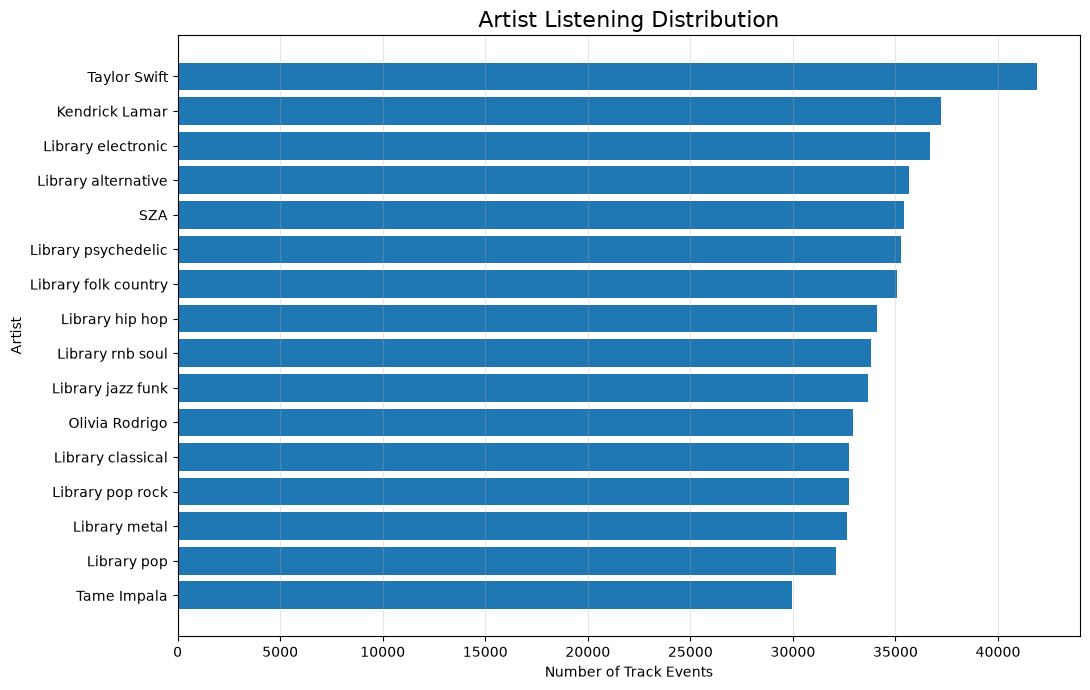

In [18]:
import matplotlib.pyplot as plt
artist_mapping = {
    artist["artist_id"]: artist["artist_name"]
    for artist in catalog["artists"]
}

artist_labels = {
    artist_mapping[artist_id]: count
    for artist_id, count in artist_counts.items()
}

artist_labels = dict(
    sorted(artist_labels.items(), key=lambda x: x[1])
)

plt.figure(figsize=(11, 7))

plt.barh(
    list(artist_labels.keys()),
    list(artist_labels.values())
)

plt.title("Artist Listening Distribution", fontsize=16)
plt.xlabel("Number of Track Events")
plt.ylabel("Artist")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

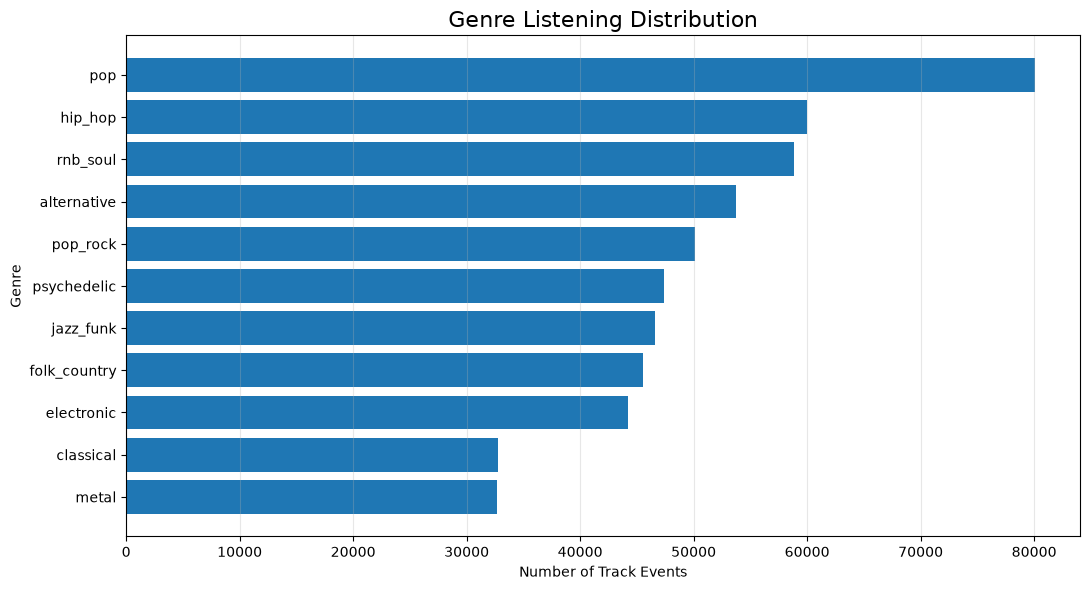

In [19]:

genre_labels = dict(
    sorted(genre_counts.items(), key=lambda x: x[1])
)

plt.figure(figsize=(11, 6))

plt.barh(
    list(genre_labels.keys()),
    list(genre_labels.values())
)

plt.title("Genre Listening Distribution", fontsize=16)
plt.xlabel("Number of Track Events")
plt.ylabel("Genre")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
# Finding unique users that listen to particular artists
artist_users = Counter()

for account in accounts:

    user_id = account["music_app_user_id"]

    
    listened_artists = set()

    for session in account["sessions"]:
        for track in session["tracks"]:
            listened_artists.add(track["artist_id"])

    
    for artist_id in listened_artists:
        artist_users[artist_id] += 1

print("Unique accounts per artist:")

for artist_id, count in artist_users.most_common():
    print(artist_id, count)


Unique accounts per artist:
A03 7286
A05 7014
A02 6921
A01 6848
A04 6663
A13 5919
A16 5899
A09 5895
A07 5875
A06 5857
A11 5841
A08 5824
A14 5822
A12 5820
A15 5806
A10 5764


In [21]:

import pandas as pd

user_artist_sets = {}

for account in accounts:
    user_id = account["music_app_user_id"]

    listened_artists = set()

    for session in account["sessions"]:
        for track in session["tracks"]:
            listened_artists.add(track["artist_id"])

    user_artist_sets[user_id] = listened_artists


# Create a binary user-artist matrix
concert_artist_ids = ["A01", "A02", "A03", "A04", "A05"]

artist_matrix = pd.DataFrame(
    {
        artist_id: [
            int(artist_id in user_artist_sets[user_id])
            for user_id in user_artist_sets
        ]
        for artist_id in concert_artist_ids
    }
)

artist_matrix.columns = [
    artist_mapping[artist_id]
    for artist_id in artist_matrix.columns
]

# Calculate audience overlap
overlap = artist_matrix.T.dot(artist_matrix)

print(overlap)


                Kendrick Lamar  Olivia Rodrigo  Taylor Swift  Tame Impala  \
Kendrick Lamar            6848            5366          5666         5192   
Olivia Rodrigo            5366            6921          6062         5341   
Taylor Swift              5666            6062          7286         5575   
Tame Impala               5192            5341          5575         6663   
SZA                       5747            5545          5849         5316   

                 SZA  
Kendrick Lamar  5747  
Olivia Rodrigo  5545  
Taylor Swift    5849  
Tame Impala     5316  
SZA             7014  


In [22]:
# Heavily overlapping accounts that listen to artists
# JACCARDS 

jaccard_matrix = overlap.copy().astype(float)

for i in range(len(overlap)):
    for j in range(len(overlap)):
        intersection = overlap.iloc[i, j]

        union = (
            overlap.iloc[i, i]
            + overlap.iloc[j, j]
            - intersection
        )

        jaccard_matrix.iloc[i, j] = intersection / union

print(jaccard_matrix.round(3))

                Kendrick Lamar  Olivia Rodrigo  Taylor Swift  Tame Impala  \
Kendrick Lamar           1.000           0.639         0.669        0.624   
Olivia Rodrigo           0.639           1.000         0.744        0.648   
Taylor Swift             0.669           0.744         1.000        0.666   
Tame Impala              0.624           0.648         0.666        1.000   
SZA                      0.708           0.661         0.692        0.636   

                  SZA  
Kendrick Lamar  0.708  
Olivia Rodrigo  0.661  
Taylor Swift    0.692  
Tame Impala     0.636  
SZA             1.000  


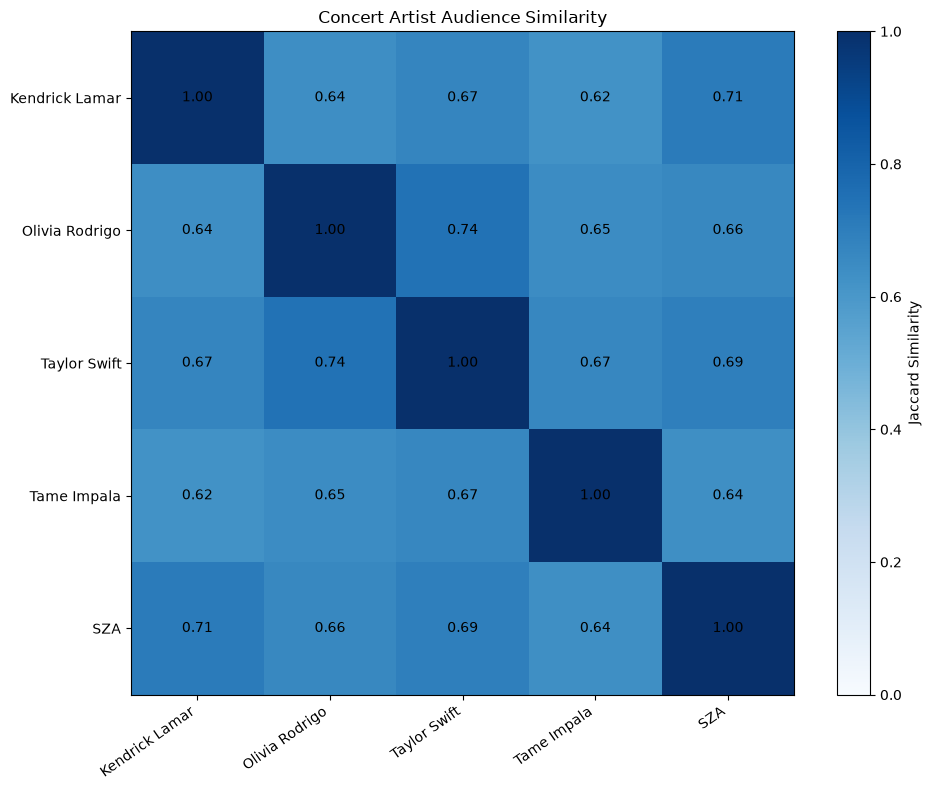

In [23]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

plt.imshow(
    jaccard_matrix.values,
    cmap="Blues",
    vmin=0,
    vmax=1
)

# Artist names on axes
plt.xticks(
    range(len(jaccard_matrix.columns)),
    jaccard_matrix.columns,
    rotation=35,
    ha="right"
)

plt.yticks(
    range(len(jaccard_matrix.index)),
    jaccard_matrix.index
)

# Display similarity values
for i in range(len(jaccard_matrix)):
    for j in range(len(jaccard_matrix)):
        plt.text(
            j, i,
            f"{jaccard_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar(label="Jaccard Similarity")
plt.title("Concert Artist Audience Similarity")
plt.tight_layout()
plt.show()


In [24]:
# This means if someone listens to olivia then likely to listen to taylor swift

In [25]:

import pandas as pd
import numpy as np

track_records = []

for account in accounts:

    user_id = account["music_app_user_id"]
    status = account["activity_status"]

    for session in account["sessions"]:

        session_id = session["session_id"]

        for track in session["tracks"]:

            record = {
                "music_app_user_id": user_id,
                "activity_status": status,
                "session_id": session_id,
                "played_at": track["played_at"],
                "artist_id": track["artist_id"],
                "genre": track["genre"],
                "track_id": track["track_id"],
                "played_ms": track["played_ms"],
                "track_ms": track["track_ms"],
                "source": track["source"],
                "saved": track["saved"]
            }

            track_records.append(record)

# Convert extracted records into a DataFrame
tracks_df = pd.DataFrame(track_records)

print("Shape:", tracks_df.shape)
print("\nColumns:")
print(tracks_df.columns.tolist())

tracks_df.head()


Shape: (551901, 11)

Columns:
['music_app_user_id', 'activity_status', 'session_id', 'played_at', 'artist_id', 'genre', 'track_id', 'played_ms', 'track_ms', 'source', 'saved']


,music_app_user_id,activity_status,session_id,played_at,artist_id,genre,track_id,played_ms,track_ms,source,saved
0,M1213C172,active,S001,2026-09-30T21:22:16Z,A11,alternative,A11_6,132490,160000,autoplay,False
1,M1213C172,active,S002,2026-09-29T00:22:53Z,A08,jazz_funk,A08_6,198000,198000,autoplay,False
2,M1213C172,active,S003,2026-09-28T00:42:34Z,A08,jazz_funk,A08_12,223698,273000,search,True
3,M1213C172,active,S003,2026-09-28T17:59:57Z,A11,alternative,A11_12,205737,232000,search,False
4,M1213C172,active,S004,2026-09-27T21:36:03Z,A16,metal,A16_10,180541,196000,search,False


In [26]:

# Account-level information

account_records = []

for account in accounts:

    sessions = account["sessions"]

    total_tracks = sum(
        len(session["tracks"])
        for session in sessions
    )

    account_records.append({
        "music_app_user_id": account["music_app_user_id"],
        "activity_status": account["activity_status"],
        "total_sessions": len(sessions),
        "total_track_events": total_tracks
    })

accounts_df = pd.DataFrame(account_records)

print(accounts_df.shape)
accounts_df.head()


(9432, 4)


,music_app_user_id,activity_status,total_sessions,total_track_events
0,M1213C172,active,53,82
1,M2B19FDA8,active,61,100
2,M24E86338,active,42,54
3,M27ADBF54,active,32,39
4,M2136A90A,active,36,47


In [27]:
from pathlib import Path

# Create processed folder if it doesn't exist
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save CSVs
accounts_df.to_csv(
    output_dir / "music_accounts.csv",
    index=False
)

tracks_df.to_csv(
    output_dir / "music_track_events.csv",
    index=False
)

print("Files saved successfully!")


Files saved successfully!
